<a href="https://colab.research.google.com/github/boseupama/Digital_Image_Processing_UB/blob/main/DIP_UB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload an image:


Saving images (4).jpg to images (4) (3).jpg
Image size: (600, 337) dtype: uint8


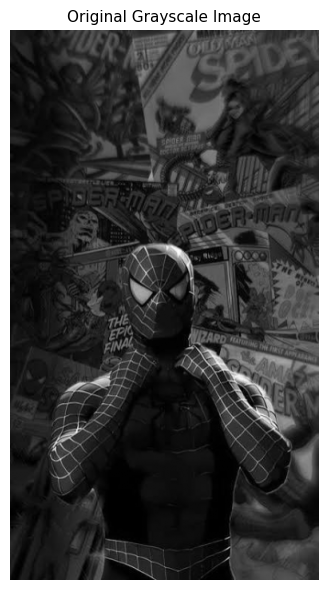

In [16]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage import data
os.makedirs("outputs", exist_ok=True)

#to load image
gray = None
try:
    from google.colab import files
    print("Upload an image:")
    uploaded = files.upload()
    if uploaded:
        path = list(uploaded.keys())[0]
        gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
except Exception as e:
    print("Upload skipped:", e)

if gray is None:
    print("Using sample image.")
    gray = data.camera()           # 512x512 grayscale sample

#to resize very large images
h, w = gray.shape
if max(h, w) > 600:
    s = 600 / max(h, w)
    gray = cv2.resize(gray, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
gray = gray.astype(np.uint8)
h, w = gray.shape
print("Image size:", gray.shape, "dtype:", gray.dtype)
#Helper functions
def to_u8(x, normalize=False):
    """Convert any array to uint8 for display."""
    x = np.asarray(x, dtype=np.float64)
    if normalize:
        x = (x - x.min()) / (x.max() - x.min() + 1e-9) * 255
    return np.clip(x, 0, 255).astype(np.uint8)

def show(images, titles, cols=3, size=4.5, save=None, suptitle=None):
    """Show images in a grid. Optionally save to outputs/<save>.png"""
    n = len(images)
    rows = int(np.ceil(n / cols))
    fig = plt.figure(figsize=(size * cols, size * rows))
    for i, (im, t) in enumerate(zip(images, titles)):
        ax = fig.add_subplot(rows, cols, i + 1)
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=11)
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=14, fontweight="bold")
    plt.tight_layout()
    if save:
        fig.savefig(f"outputs/{save}.png", dpi=150, bbox_inches="tight")
    plt.show()

def conv(img, kernel):
    """2D correlation/convolution with replicated borders, float output."""
    k = np.asarray(kernel, dtype=np.float64)
    return cv2.filter2D(img.astype(np.float64), cv2.CV_64F, k, borderType=cv2.BORDER_REPLICATE)


show([gray], ["Original Grayscale Image"], cols=1, size=6, save="00_input")

Number of gray levels (rows of the table): 8
  Row 1: gray level r_k = 0
         No. of pixels n_k at gray level 0 = 9
  Row 2: gray level r_k = 1
         No. of pixels n_k at gray level 1 = 8
  Row 3: gray level r_k = 2
         No. of pixels n_k at gray level 2 = 11
  Row 4: gray level r_k = 3
         No. of pixels n_k at gray level 3 = 4
  Row 5: gray level r_k = 4
         No. of pixels n_k at gray level 4 = 10
  Row 6: gray level r_k = 5
         No. of pixels n_k at gray level 5 = 15
  Row 7: gray level r_k = 6
         No. of pixels n_k at gray level 6 = 4
  Row 8: gray level r_k = 7
         No. of pixels n_k at gray level 7 = 3
Highest gray level L-1 (press Enter to use the largest entered level, 7): 7

          Gray level       No. of pixels         PDF = n_k/n      Cumulative s_k             s_k x 7  Equalization level
                   0                   9              0.1406              0.1406                0.98                   1
                   1             

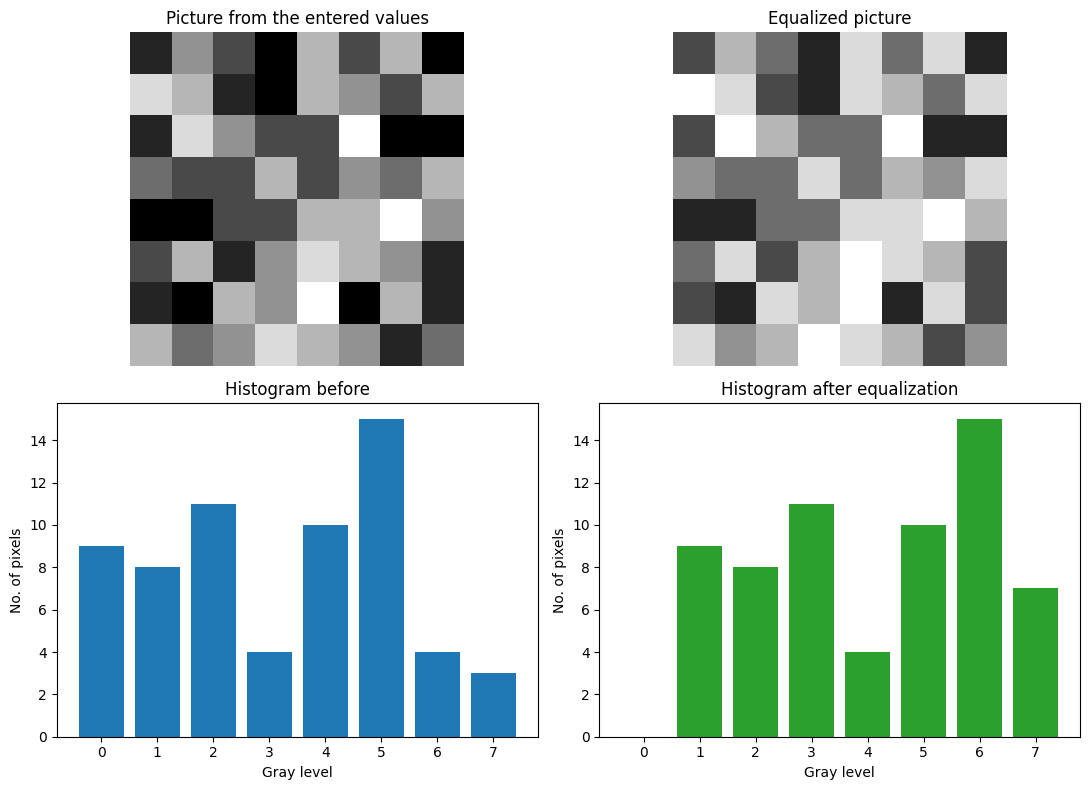


(Image) first 10 gray levels that occur:
          Gray level       No. of pixels         PDF = n_k/n      Cumulative s_k           s_k x 255  Equalization level
                   0                2332              0.0115              0.0115                2.94                   3
                   1                2741              0.0136              0.0251                6.40                   6
                   2                1726              0.0085              0.0336                8.57                   9
                   3                1394              0.0069              0.0405               10.33                  10
                   4                1332              0.0066              0.0471               12.01                  12
                   5                1403              0.0069              0.0540               13.78                  14
                   6                1815              0.0090              0.0630               16.07           

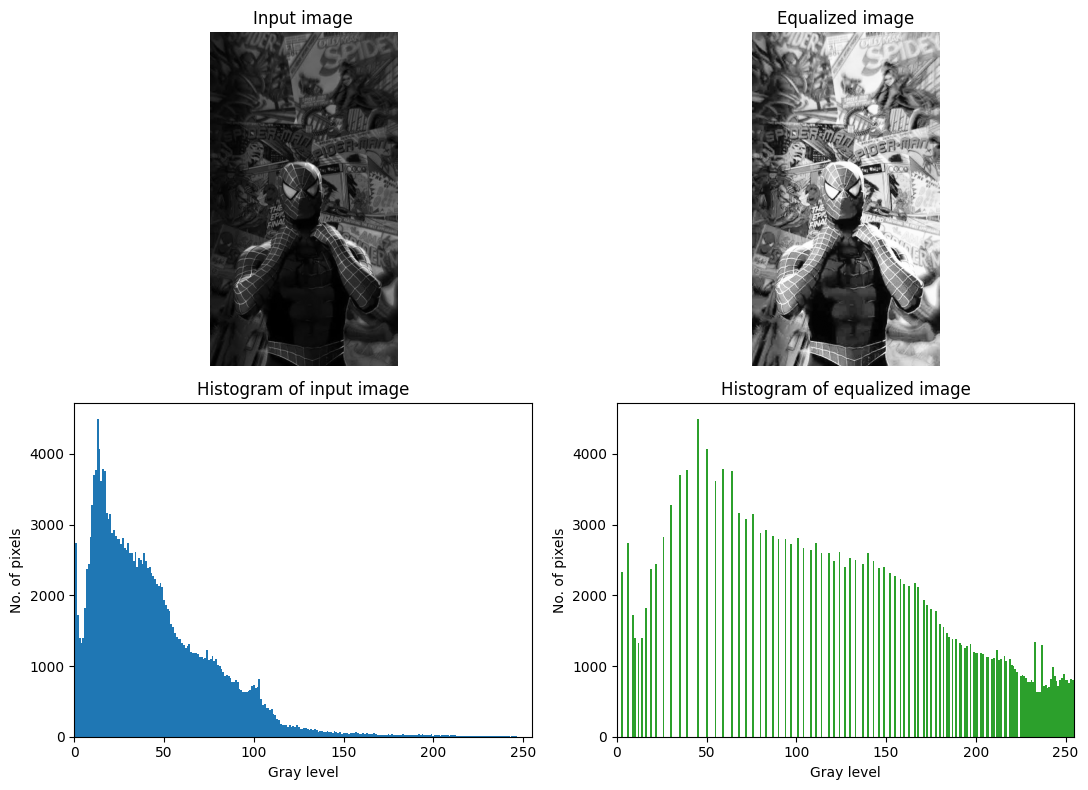

In [21]:
# 1.Histogram equalization and the histogram equalizer
def equalization_table(n_k, Lmax):
    n = n_k.sum()                                   #n : total number of pixels
    pdf = n_k / n                                   #p_r(r_k) = n_k / n
    cum = np.cumsum(n_k)
    sk = cum / n                                    #s_k = cumulative sum of the PDF
    out = cum * Lmax / n                            #s_k x (L-1)
    level = np.floor(out + 0.5).astype(int)         #equalized level
    return pdf, sk, out, level

def histogram_equalizer(img, L=256):
    n_k = np.bincount(img.ravel(), minlength=L)     #n_k for gray levels 0 .. L-1
    pdf, sk, out, level = equalization_table(n_k, L - 1)
    return level[img].astype(np.uint8), n_k, pdf, sk, out, level


#table for values entered by the user
rows = int(input("Number of gray levels (rows of the table): "))
gl = np.zeros(rows, dtype=int)
n_in = np.zeros(rows, dtype=int)
for i in range(rows):
    gl[i] = int(input(f"  Row {i + 1}: gray level r_k = "))
    n_in[i] = int(input(f"         No. of pixels n_k at gray level {gl[i]} = "))

order = np.argsort(gl)                              #the cumulative sum needs ascending gray levels
gl, n_in = gl[order], n_in[order]
if len(set(gl.tolist())) != rows:
    raise ValueError("Each gray level must be entered only once.")
if (gl < 0).any() or (n_in < 0).any() or n_in.sum() == 0:
    raise ValueError("Gray levels and pixel counts must be non-negative, and the counts not all zero.")

txt = input(f"Highest gray level L-1 (press Enter to use the largest entered level, {gl.max()}): ").strip()
Lmax = int(txt) if txt else int(gl.max())
if Lmax < gl.max():
    raise ValueError("The highest gray level cannot be smaller than the gray levels entered.")

pdf_in, sk_in, out_in, lvl_in = equalization_table(n_in, Lmax)

head = ["Gray level", "No. of pixels", "PDF = n_k/n", "Cumulative s_k", f"s_k x {Lmax}", "Equalization level"]
print("\n" + "".join(f"{h:>20}" for h in head))
for i in range(rows):
    print(f"{gl[i]:>20}{n_in[i]:>20}{pdf_in[i]:>20.4f}{sk_in[i]:>20.4f}{out_in[i]:>20.2f}{lvl_in[i]:>20}")
print(f"{'Total':>20}{n_in.sum():>20}{pdf_in.sum():>20.4f}")

#to apply the user's values on a picture
N = int(n_in.sum())
pixels = np.repeat(gl, n_in)                                        #n_k copies of each gray level r_k
np.random.default_rng(0).shuffle(pixels)                            #spread the pixels over the picture
ph = max(d for d in range(1, int(np.sqrt(N)) + 1) if N % d == 0)    #picture height
user_img = pixels.reshape(ph, N // ph)

lut = np.zeros(Lmax + 1, dtype=int)                                 #gray level > equalization level
lut[gl] = lvl_in
user_eq = lut[user_img]

n_before = np.bincount(user_img.ravel(), minlength=Lmax + 1)
n_after = np.bincount(user_eq.ravel(), minlength=Lmax + 1)

if user_img.size <= 400:                                            #to print small pictures as matrices
    print("\nPicture (gray levels):\n", user_img)
    print("\nEqualized picture (equalization levels):\n", user_eq)

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0, 0].imshow(user_img, cmap="gray", vmin=0, vmax=Lmax, interpolation="nearest")
ax[0, 0].set_title("Picture from the entered values"); ax[0, 0].axis("off")
ax[0, 1].imshow(user_eq, cmap="gray", vmin=0, vmax=Lmax, interpolation="nearest")
ax[0, 1].set_title("Equalized picture"); ax[0, 1].axis("off")
ax[1, 0].bar(range(Lmax + 1), n_before, width=0.8);                    ax[1, 0].set_title("Histogram before")
ax[1, 1].bar(range(Lmax + 1), n_after, width=0.8, color="tab:green");  ax[1, 1].set_title("Histogram after equalization")
for a in ax[1]:
    a.set_xlabel("Gray level"); a.set_ylabel("No. of pixels")
    if Lmax <= 31: a.set_xticks(range(Lmax + 1))
plt.tight_layout()
fig.savefig("outputs/01_user_picture_equalization.png", dpi=150, bbox_inches="tight")
plt.show()

#to apply on the uploaded image
eq, n_k, pdf, sk, out, level = histogram_equalizer(gray)
n_eq = np.bincount(eq.ravel(), minlength=256)

print("\n(Image) first 10 gray levels that occur:")
print("".join(f"{h:>20}" for h in ["Gray level", "No. of pixels", "PDF = n_k/n", "Cumulative s_k", "s_k x 255", "Equalization level"]))
for r in np.nonzero(n_k)[0][:10]:
    print(f"{r:>20}{n_k[r]:>20}{pdf[r]:>20.4f}{sk[r]:>20.4f}{out[r]:>20.2f}{level[r]:>20}")

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255); ax[0, 0].set_title("Input image");     ax[0, 0].axis("off")
ax[0, 1].imshow(eq,   cmap="gray", vmin=0, vmax=255); ax[0, 1].set_title("Equalized image"); ax[0, 1].axis("off")
ax[1, 0].bar(range(256), n_k,  width=1);                    ax[1, 0].set_title("Histogram of input image")
ax[1, 1].bar(range(256), n_eq, width=1, color="tab:green"); ax[1, 1].set_title("Histogram of equalized image")
for a in ax[1]:
    a.set_xlim(0, 255); a.set_xlabel("Gray level"); a.set_ylabel("No. of pixels")
plt.tight_layout()
fig.savefig("outputs/01_histogram_equalization.png", dpi=150, bbox_inches="tight")
plt.show()

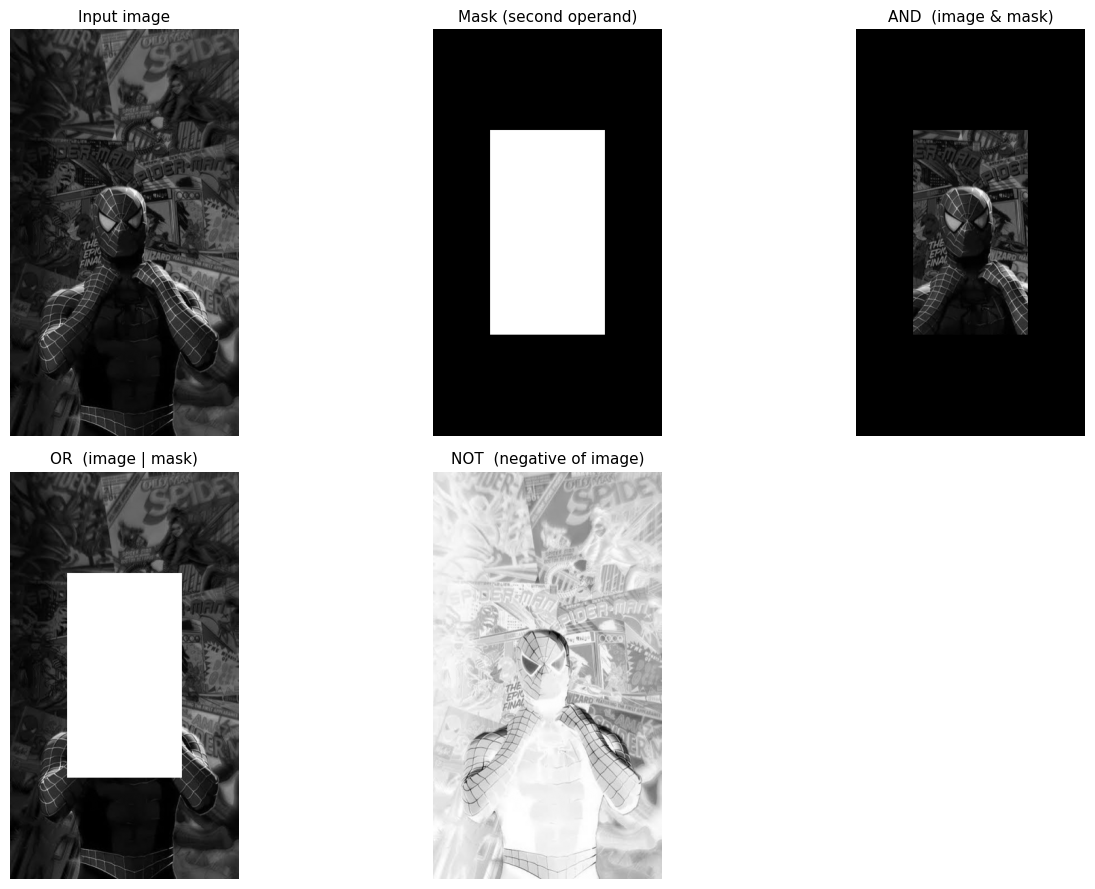

In [22]:
#2.to perform AND, OR and NOT operations on an image
mask = np.zeros_like(gray)
x1, y1 = w // 4, h // 4            #top-left corner
x2, y2 = 3 * w // 4, 3 * h // 4    #bottom-right corner
cv2.rectangle(mask, (x1, y1), (x2, y2), 255, -1)   #-1 = filled

img_and = cv2.bitwise_and(gray, mask)      #keeps image inside the rectangle
img_or  = cv2.bitwise_or(gray, mask)       #forces rectangle region to white
img_not = cv2.bitwise_not(gray)            #negative of the image

show([gray, mask, img_and, img_or, img_not],
     ["Input image", "Mask (second operand)", "AND  (image & mask)",
      "OR  (image | mask)", "NOT  (negative of image)"],
     cols=3, save="02_logic_operations")

Addition  F + G
[[ 10 200  15]
 [  6   0  10]
 [  8  10  15]]

Subtraction  F - G
[[ 0  0  5]
 [ 2  0 10]
 [ 8  0  0]]

Multiplication  F x G
[[  0 255  50]
 [  8   0   0]
 [  0   0  50]]

Division  F / G
[[0 1 2]
 [2 0 0]
 [0 0 0]]



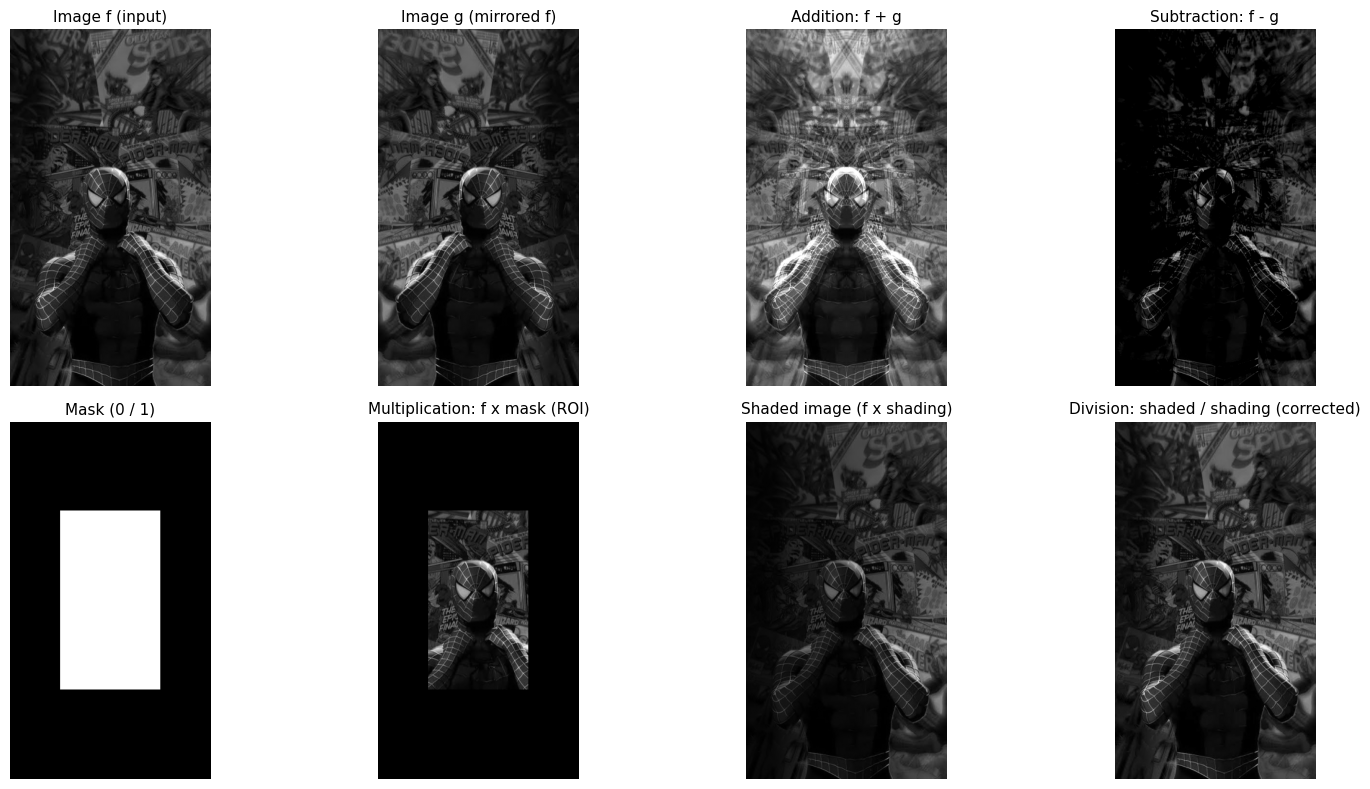

In [23]:
#3.to perform the four arithmetic operations on an image
def image_arithmetic(f, g, op):
    f = np.asarray(f, dtype=np.float64)
    g = np.asarray(g, dtype=np.float64)
    if op == "add":
        r = f + g
    elif op == "sub":
        r = f - g
    elif op == "mul":
        r = f * g
    elif op == "div":
        with np.errstate(divide="ignore", invalid="ignore"):
            r = f / g
        r[~np.isfinite(r)] = 0                      #infinity
    r = np.round(r)                                 #round off floating-point results
    return np.clip(r, 0, 255).astype(np.uint8)      #above 255 -> 255, below 0 -> 0


#to check with the matrices
F = np.array([[0, 100, 10], [4, 0, 10], [8, 0, 5]])
G = np.array([[10, 100, 5], [2, 0, 0], [0, 10, 10]])
for name, op in [("Addition  F + G", "add"), ("Subtraction  F - G", "sub"),
                 ("Multiplication  F x G", "mul"), ("Division  F / G", "div")]:
    print(name); print(image_arithmetic(F, G, op)); print()

#Apply the four operations on the image
g = cv2.flip(gray, 1)                                   # 2nd image: mirrored copy of the input
add_img = image_arithmetic(gray, g, "add")              # addition
sub_img = image_arithmetic(gray, g, "sub")              # subtraction

roi = np.zeros_like(gray, dtype=np.float64)             # multiplication: masking / ROI (mask = 0 or 1)
roi[h // 4: 3 * h // 4, w // 4: 3 * w // 4] = 1
mul_img = image_arithmetic(gray, roi, "mul")

shade = np.tile(np.linspace(0.3, 1.0, w), (h, 1))       # division: shading correction
shaded = image_arithmetic(gray, shade, "mul")           # image with uneven shading (f x shade)
div_img = image_arithmetic(shaded, shade, "div")        # corrected image

show([gray, g, add_img, sub_img, roi * 255, mul_img, shaded, div_img],
     ["Image f (input)", "Image g (mirrored f)", "Addition: f + g", "Subtraction: f - g",
      "Mask (0 / 1)", "Multiplication: f x mask (ROI)",
      "Shaded image (f x shading)", "Division: shaded / shading (corrected)"],
     cols=4, size=4, save="03_arithmetic_operations")

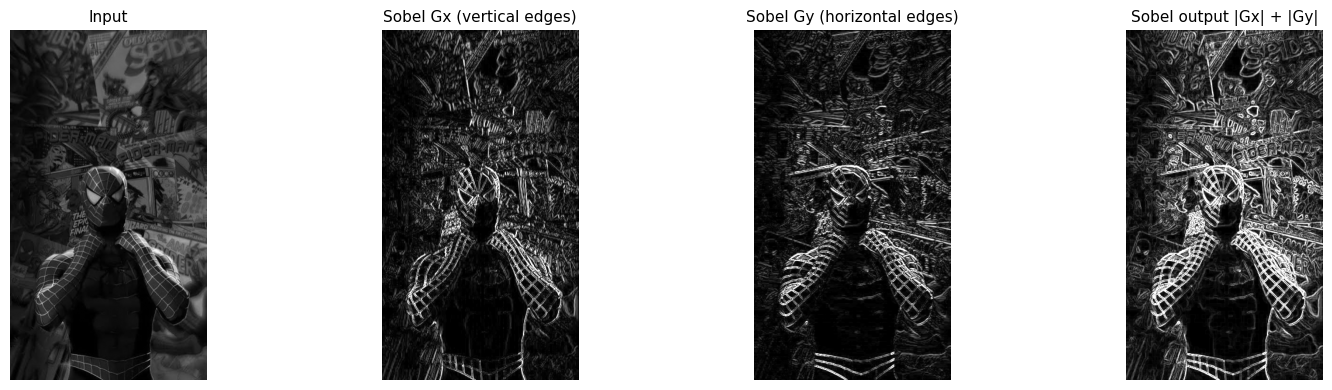

In [25]:
# 4.Applying masks to an image
#a.Sobel operator
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])            # to compute dP/dx
sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])          # to compute dP/dy
gx = conv(gray, sobel_x)
gy = conv(gray, sobel_y)
sobel_out = np.abs(gx) + np.abs(gy)         # edge strength |Gx| + |Gy|

show([gray, to_u8(np.abs(gx)), to_u8(np.abs(gy)), to_u8(sobel_out)],
     ["Input", "Sobel Gx (vertical edges)", "Sobel Gy (horizontal edges)", "Sobel output |Gx| + |Gy|"],
     cols=4, size=4, save="04a_sobel")



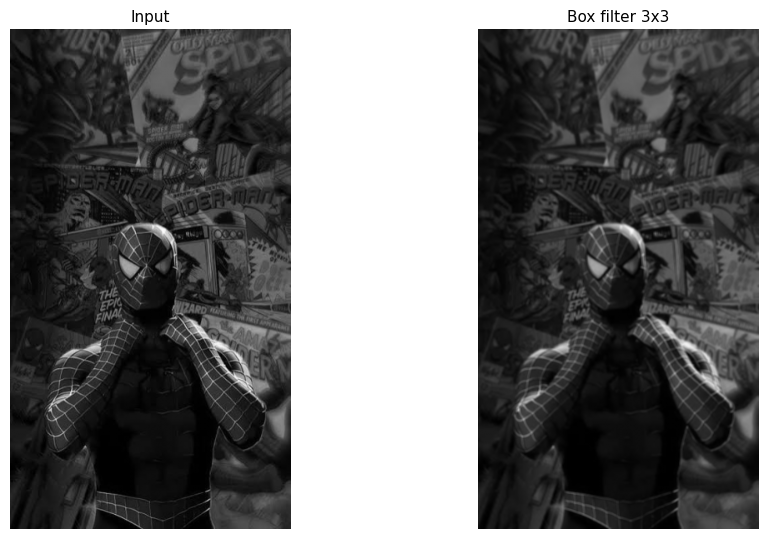

In [26]:
#4b. Box filter
box = np.ones((3, 3)) / 9
show([gray, to_u8(conv(gray, box))], ["Input", "Box filter 3x3"], cols=2, size=5.5, save="04b_box")



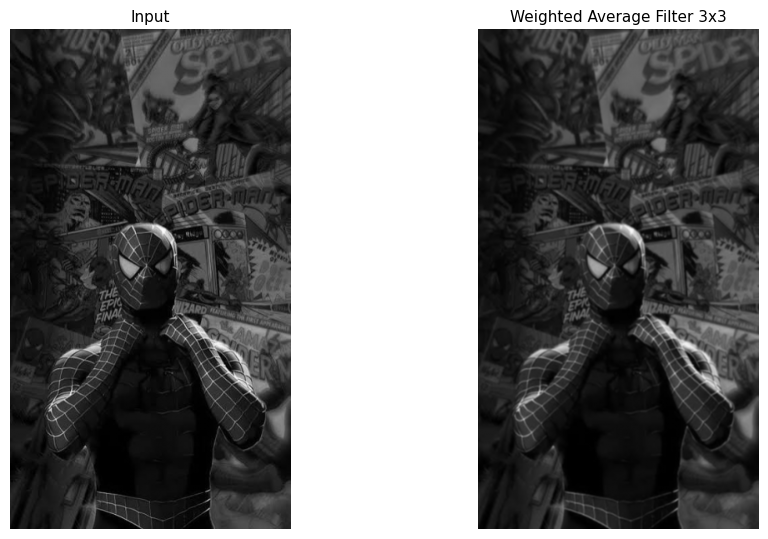

In [28]:
# 4c.Weighted average filter
weighted = np.array([[1, 2, 1],
                     [2, 4, 2],
                     [1, 2, 1]]) / 16
show([gray, to_u8(conv(gray, weighted))], ["Input", "Weighted Average Filter 3x3"],
     cols=2, size=5.5, save="04c_weighted_average")



5x5 Gaussian mask (sigma = 1):
 [[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]


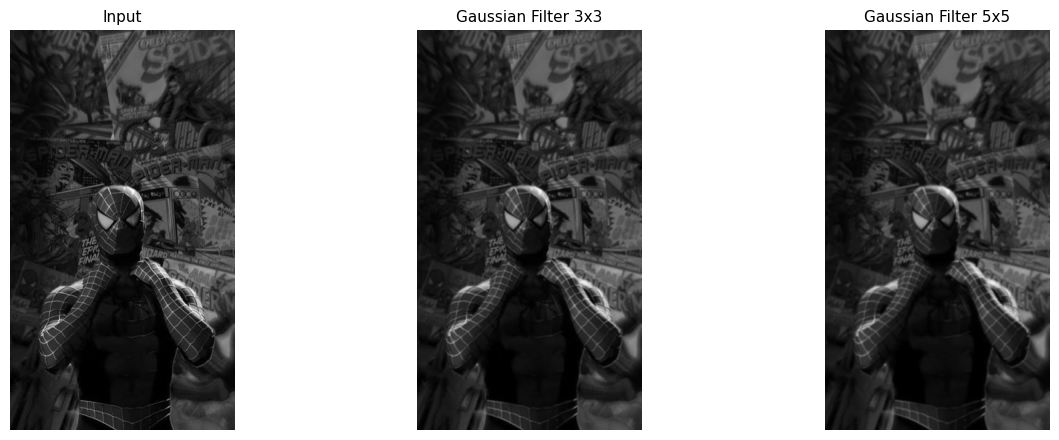

In [31]:
# 4d. Gaussian filter mask
def gaussian_mask(size, sigma):
    a = np.arange(size) - size // 2
    x, y = np.meshgrid(a, a)
    G = np.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2)) / (2 * np.pi * sigma ** 2)
    return G / G.sum()

gauss3 = weighted
gauss5 = gaussian_mask(5, 1.0)               # built from the Gaussian formula (sigma = 1)
print("5x5 Gaussian mask (sigma = 1):\n", np.round(gauss5, 4))
show([gray, to_u8(conv(gray, gauss3)), to_u8(conv(gray, gauss5))],
     ["Input", "Gaussian Filter 3x3", "Gaussian Filter 5x5"],
     cols=3, size=4.5, save="04d_gaussian")



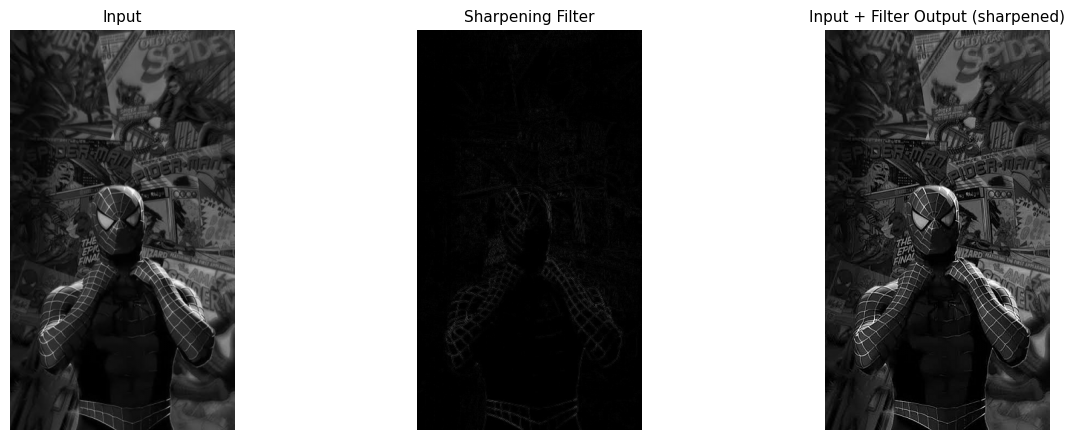

In [33]:
# 4e. Sharpening filter
sharpen = np.array([[-1, -1, -1],
                    [-1,  8, -1],
                    [-1, -1, -1]]) / 9
detail = conv(gray, sharpen)                 #intensity transitions
sharpened = gray + detail                    #centre of the mask is positive- add to the input
show([gray, to_u8(np.abs(detail)), to_u8(sharpened)],
     ["Input", "Sharpening Filter", "Input + Filter Output (sharpened)"],
     cols=3, size=4.5, save="04e_sharpening")




 at pixel (2,2):  Box/Mean = 4.67 | Weighted = 5.0625 | Median = 5 | Min = 0 | Max = 9


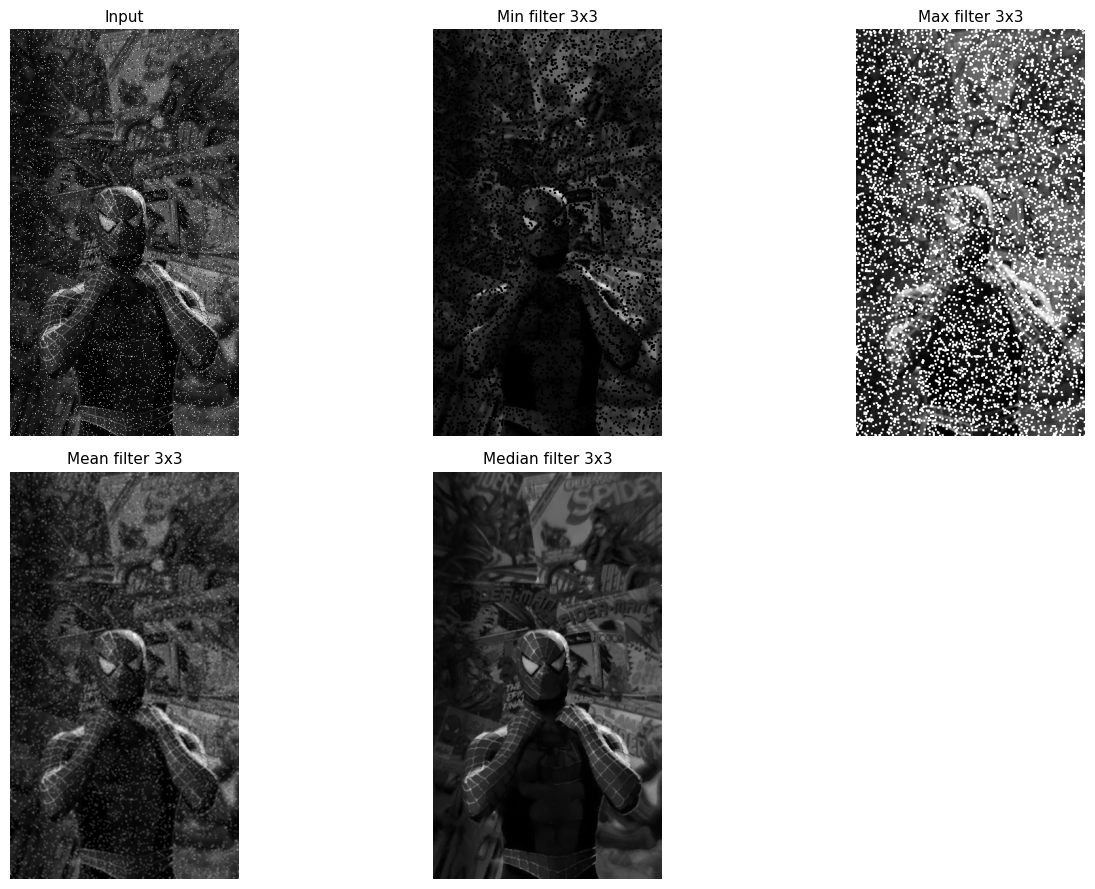

In [34]:
# 4f. Min, Max, Mean, Median filters
ex5 = np.array([[1, 8, 8, 0, 7],
                [4, 7, 9, 5, 7],
                [5, 4, 6, 8, 6],
                [4, 2, 0, 1, 5],
                [0, 1, 0, 2, 0]])
print("\n at pixel (2,2):  Box/Mean =", round(conv(ex5, box)[2, 2], 2),
      "| Weighted =", round(conv(ex5, weighted)[2, 2], 4),
      "| Median =", ndimage.median_filter(ex5, size=3, mode="nearest")[2, 2],
      "| Min =", ndimage.minimum_filter(ex5, size=3, mode="nearest")[2, 2],
      "| Max =", ndimage.maximum_filter(ex5, size=3, mode="nearest")[2, 2])

# Salt-and-pepper noise
rng = np.random.default_rng(42)
noisy = gray.copy()
r = rng.random(gray.shape)
noisy[r < 0.03] = 0          # pepper
noisy[r > 0.97] = 255        # salt

min_f    = ndimage.minimum_filter(noisy, size=3, mode="nearest")
max_f    = ndimage.maximum_filter(noisy, size=3, mode="nearest")
mean_f   = ndimage.uniform_filter(noisy.astype(np.float64), size=3, mode="nearest")
median_f = ndimage.median_filter(noisy, size=3, mode="nearest")

show([noisy, min_f, max_f, mean_f, median_f],
     ["Input", "Min filter 3x3", "Max filter 3x3",
      "Mean filter 3x3", "Median filter 3x3"],
     cols=3, size=4.5, save="04f_min_max_mean_median")

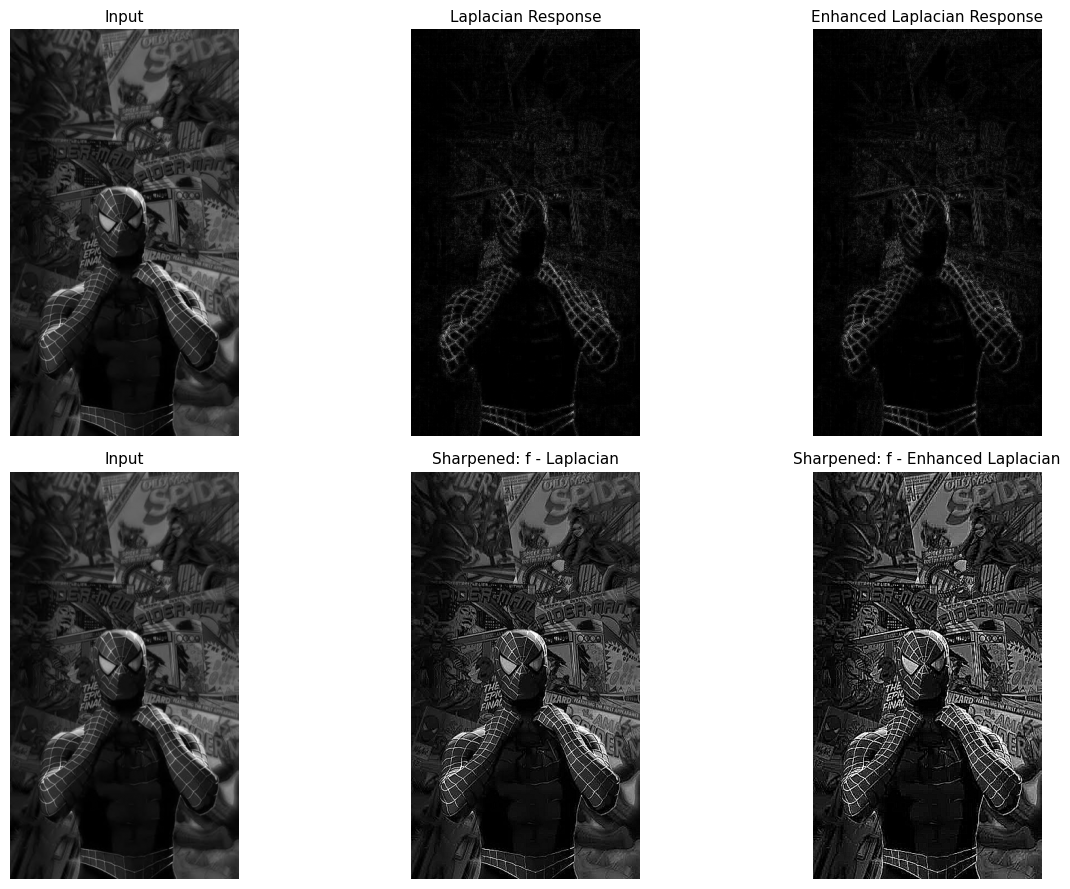

In [38]:
#Laplacian mask, enhanced Laplacian mask and high-boost mask
f = gray.astype(np.float64)

#Laplacian mask
lap = np.array([[0,  1, 0],
                [1, -4, 1],
                [0,  1, 0]])
# Enhanced Laplacian mask
lap_en = np.array([[1,  1, 1],
                   [1, -8, 1],
                   [1,  1, 1]])

L1 = conv(gray, lap)
L2 = conv(gray, lap_en)
sharp_L1 = np.clip(f - L1, 0, 255)      # centre is negative - subtract
sharp_L2 = np.clip(f - L2, 0, 255)

show([gray, to_u8(np.abs(L1), normalize=True), to_u8(np.abs(L2), normalize=True),
      gray, sharp_L1, sharp_L2],
     ["Input", "Laplacian Response", "Enhanced Laplacian Response",
      "Input", "Sharpened: f - Laplacian", "Sharpened: f - Enhanced Laplacian"],
     cols=3, save="05ab_laplacian")

High-boost mask for A=1.5 (times 1/9):
 [[-1.  -1.  -1. ]
 [-1.  12.5 -1. ]
 [-1.  -1.  -1. ]]


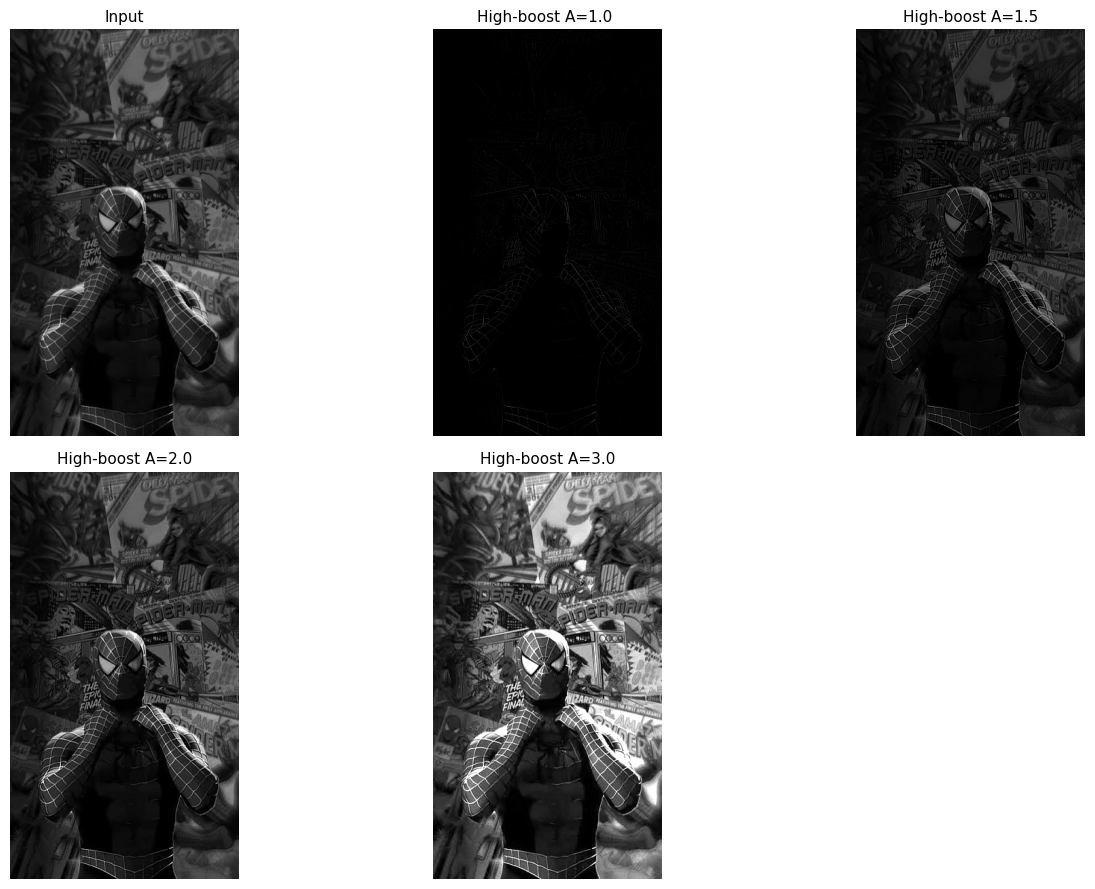

In [44]:
#High-boost mask
def high_boost_kernel(A):
    k = -np.ones((3, 3))
    k[1, 1] = 9 * A - 1
    return k / 9

results, titles = [gray], ["Input"]
for A in [1.0, 1.5, 2.0, 3.0]:
    k = high_boost_kernel(A)
    results.append(np.clip(conv(gray, k), 0, 255))
    titles.append(f"High-boost A={A}" + (" " if A == 1.0 else ""))
    if A == 1.5:
        print("High-boost mask for A=1.5 (times 1/9):\n", np.round(k * 9, 2))

show(results, titles, cols=3, save="05c_high_boost")
